# Big Data Analytics for E-Commerce: Customer Behaviour, Sales Trends and Product Affinity Using Apache Spark
**Course project — one complete notebook: local Online Retail data → quality checks → cleaning → Spark analytics → RFM → K-Means clustering → product affinity → Pareto analysis → charts → conclusion.**

* Environment: Windows 11, Python, Java 17, local PySpark (no cloud, no GPU), Jupyter Notebook.
* Dataset: the existing `Online Retail.xlsx` file already present in this project folder (used as-is; never modified).
* Rule used throughout: heavy work stays inside Spark; only small aggregated result tables are collected to the driver for display/plotting (safe on 8 GB RAM).

## 1. Introduction
### 1.1 Background
E-commerce shops record every transaction: what was bought, how many units, at what price, by whom, when and from which country. After a year this is hundreds of thousands of rows — classic "big data" for a student project: too clumsy for manual spreadsheets, but ideal for a distributed engine like Apache Spark.

### 1.2 Problem statement
Raw retail data is messy (missing customer IDs, duplicate rows, cancelled orders, returns with negative quantities, zero prices) and raw rows do not answer business questions by themselves. We need a repeatable pipeline that cleans the data and turns it into decisions: which products earn the most, where revenue comes from, how sales evolve over time, who the best customers are, and which products are bought together.

### 1.3 Objectives
1. Load the real local retail dataset into Spark.
2. Assess and document its data-quality problems with real counts.
3. Clean it with justified, visible steps (before/after counts).
4. Engineer revenue and date features and organise the work as Bronze → Silver → Gold.
5. Answer business questions with Spark DataFrames and Spark SQL.
6. Segment customers with RFM analysis and find product affinities (support / confidence / lift).

### 1.4 Real-world relevance
The outputs map directly to retail decisions: stock planning (top products), marketing focus (top countries, season peaks), customer retention (RFM segments) and cross-selling ("customers who bought X also bought Y").

### 1.5 Scope
One year of UK-based online retail transactions (Dec 2010 – Dec 2011, ~542k rows). Descriptive analytics only — no machine-learning model training.

### 1.6 Why Apache Spark?
Spark processes data in parallel across CPU cores, keeps working sets in memory, and offers one API for ETL (DataFrames), SQL queries and aggregations. Even on a laptop (`local[2]`, 2 GB driver, 8 shuffle partitions) it handles this dataset in seconds per step, and the same code would scale to a cluster.

## 2. Environment setup
Check the installed software versions, then start a conservative local Spark session (2 cores, 2 GB driver — fits 8 GB RAM) and verify it works.

In [1]:
import platform, subprocess
import pyspark
print("Python   :", platform.python_version())
print("PySpark  :", pyspark.__version__)
try:
    out = subprocess.run(["java", "-version"], capture_output=True, text=True)
    print("Java     :", (out.stderr or out.stdout).strip().splitlines()[0])
except Exception as e:
    print("Java check failed:", e)

Python   : 3.14.6
PySpark  : 3.5.5
Java     : openjdk version "17.0.20.1" 2026-08-18


In [2]:
from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName("BDA-Ecommerce-Analytics")
         .master("local[2]")                      # 2 worker threads: enough, keeps RAM free
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")   # small shuffle parallelism for a laptop
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")            # hide noisy INFO logs
print("Spark version:", spark.version)
print("Running on   :", spark.sparkContext.master)

Spark version: 3.5.5
Running on   : local[2]


In [3]:
# Smoke test: build a tiny DataFrame with spark.range (runs inside the JVM)
# and run a SQL query on it. If both work, the session is healthy.
spark.range(5).show()
spark.sql("SELECT 1 + 1 AS two, 'spark-ok' AS status").show()

+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+

+---+--------+
|two|  status|
+---+--------+
|  2|spark-ok|
+---+--------+



## 3. Load the actual local dataset
The project folder already contains the dataset. We locate it automatically (no hard-coded path assumptions beyond the notebook folder), inspect it, convert the Excel sheet to a plain CSV **cache copy** (streaming, low memory — the original `.xlsx` is never modified), and read it into Spark with an explicit schema.

In [4]:
import glob, os
xlsx_files = glob.glob(os.path.join(os.getcwd(), "*.xlsx"))
print("Excel files found in project folder:", xlsx_files)
if not xlsx_files:
    raise FileNotFoundError(
        "Dataset not found: copy 'Online Retail.xlsx' (the UCI Online Retail file) "
        "into the same folder as this notebook and re-run. "
        "The original Excel file is only ever read, never modified.")
DATA_XLSX = xlsx_files[0]
size_mb = os.path.getsize(DATA_XLSX) / (1024 * 1024)
print("Using dataset file:", os.path.basename(DATA_XLSX), f"({size_mb:.1f} MB)")

Excel files found in project folder: ['D:\\BDA PROJECT\\Online Retail.xlsx']
Using dataset file: Online Retail.xlsx (22.6 MB)


In [5]:
# One-off Excel -> CSV conversion (streaming read, row by row, so RAM stays low).
# The CSV is a technical cache; re-used on re-runs if it already exists.
import csv, time
import openpyxl

CSV_CACHE = os.path.join(os.getcwd(), "online_retail_cache.csv")
if os.path.exists(CSV_CACHE) and os.path.getsize(CSV_CACHE) > 0:
    print("Cache CSV already exists, skipping conversion:", os.path.basename(CSV_CACHE))
else:
    t0 = time.time()
    wb = openpyxl.load_workbook(DATA_XLSX, read_only=True, data_only=True)
    ws = wb["Online Retail"]
    n = 0
    with open(CSV_CACHE, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        for row in ws.iter_rows(values_only=True):
            if n == 0:
                w.writerow(list(row))          # header row
            else:
                out = []
                for v in row:
                    if v is None:
                        out.append("")
                    elif hasattr(v, "strftime"):   # InvoiceDate datetime -> text
                        out.append(v.strftime("%Y-%m-%d %H:%M:%S"))
                    else:
                        out.append(v)
                w.writerow(out)
            n += 1
    wb.close()
    print(f"Converted {n - 1} data rows in {time.time() - t0:.0f} seconds ->", os.path.basename(CSV_CACHE))

Cache CSV already exists, skipping conversion: online_retail_cache.csv


In [6]:
# Read the CSV into Spark with an EXPLICIT schema (reliable types, no guessing).
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType, TimestampType

retail_schema = StructType([
    StructField("InvoiceNo",   StringType(),    True),   # string: holds 'C536379' cancellations too
    StructField("StockCode",   StringType(),    True),   # string: holds letters like '85123A', 'D', 'B'
    StructField("Description", StringType(),    True),
    StructField("Quantity",    IntegerType(),   True),
    StructField("InvoiceDate", TimestampType(), True),
    StructField("UnitPrice",   DoubleType(),    True),
    StructField("CustomerID",  IntegerType(),   True),   # null when missing
    StructField("Country",     StringType(),    True),
])
bronze_raw = (spark.read
              .option("header", "true")
              .option("nullValue", "")
              .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
              .schema(retail_schema)
              .csv(CSV_CACHE))
raw_count = bronze_raw.count()
print("Real filename :", os.path.basename(DATA_XLSX))
print("Record count  :", raw_count)
print("Column names  :", bronze_raw.columns)
bronze_raw.printSchema()

Real filename : Online Retail.xlsx
Record count  : 541909
Column names  : ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
root
 |-- InvoiceNo: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: timestamp (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- CustomerID: integer (nullable = true)
 |-- Country: string (nullable = true)



In [7]:
# First 10 rows of the real dataset
bronze_raw.show(10, truncate=False)

+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+
|InvoiceNo|StockCode|Description                        |Quantity|InvoiceDate        |UnitPrice|CustomerID|Country       |
+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+
|536365   |85123A   |WHITE HANGING HEART T-LIGHT HOLDER |6       |2010-12-01 08:26:00|2.55     |17850     |United Kingdom|
|536365   |71053    |WHITE METAL LANTERN                |6       |2010-12-01 08:26:00|3.39     |17850     |United Kingdom|
|536365   |84406B   |CREAM CUPID HEARTS COAT HANGER     |8       |2010-12-01 08:26:00|2.75     |17850     |United Kingdom|
|536365   |84029G   |KNITTED UNION FLAG HOT WATER BOTTLE|6       |2010-12-01 08:26:00|3.39     |17850     |United Kingdom|
|536365   |84029E   |RED WOOLLY HOTTIE WHITE HEART.     |6       |2010-12-01 08:26:00|3.39     |17850     |United Kingdom|
|536365   |22752

In [8]:
# Basic statistics of the numeric columns (runs inside Spark)
bronze_raw.describe().show()

+-------+-----------------+------------------+--------------------+------------------+----------------+------------------+-----------+
|summary|        InvoiceNo|         StockCode|         Description|          Quantity|       UnitPrice|        CustomerID|    Country|
+-------+-----------------+------------------+--------------------+------------------+----------------+------------------+-----------+
|  count|           541909|            541909|              540455|            541909|          541909|            406829|     541909|
|   mean| 559965.752026781|27623.240210938104|             20713.0|  9.55224954743324|4.61111362608298|15287.690570239585|       NULL|
| stddev|13428.41728080314|16799.737628427676|                NULL|218.08115785023458|96.7598530611795|1713.6003033215982|       NULL|
|    min|           536365|             10002| 4 PURPLE FLOCK D...|            -80995|       -11062.06|             12346|  Australia|
|    max|          C581569|                 m|   wrongl

## 4. Raw data quality assessment
Before cleaning, we measure every problem on the real data: missing values, exact duplicates, missing customers, invalid dates, negative quantities, invalid prices, cancelled invoices and special (non-product) stock codes.

In [9]:
import pyspark.sql.functions as F

print("--- Missing values per column (real counts) ---")
bronze_raw.select([(F.sum(F.col(c).isNull().cast("int"))).alias(c) for c in bronze_raw.columns]).show()

--- Missing values per column (real counts) ---


+---------+---------+-----------+--------+-----------+---------+----------+-------+
|InvoiceNo|StockCode|Description|Quantity|InvoiceDate|UnitPrice|CustomerID|Country|
+---------+---------+-----------+--------+-----------+---------+----------+-------+
|        0|        0|       1454|       0|          0|        0|    135080|      0|
+---------+---------+-----------+--------+-----------+---------+----------+-------+



In [10]:
exact_dupes = raw_count - bronze_raw.dropDuplicates().count()
print(f"Exact duplicate rows : {exact_dupes} ({100.0 * exact_dupes / raw_count:.2f}% of raw data)")
print("Representative duplicated rows:")
bronze_raw.groupBy(bronze_raw.columns).count().filter("count > 1").limit(5).show(truncate=False)

Exact duplicate rows : 5268 (0.97% of raw data)
Representative duplicated rows:


+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+-----+
|InvoiceNo|StockCode|Description                        |Quantity|InvoiceDate        |UnitPrice|CustomerID|Country       |count|
+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+-----+
|536409   |21866    |UNION JACK FLAG LUGGAGE TAG        |1       |2010-12-01 11:45:00|1.25     |17908     |United Kingdom|2    |
|536412   |22569    |FELTCRAFT CUSHION BUTTERFLY        |2       |2010-12-01 11:49:00|3.75     |17920     |United Kingdom|2    |
|536412   |22902    |TOTE BAG I LOVE LONDON             |7       |2010-12-01 11:49:00|2.1      |17920     |United Kingdom|2    |
|536412   |21706    |FOLDING UMBRELLA RED/WHITE POLKADOT|1       |2010-12-01 11:49:00|4.95     |17920     |United Kingdom|2    |
|536528   |22865    |HAND WARMER OWL DESIGN             |1       |2010-12-01 13:17:00|2.1      |1

In [11]:
null_cust = bronze_raw.filter(F.col("CustomerID").isNull()).count()
print(f"Rows with missing CustomerID : {null_cust} ({100.0 * null_cust / raw_count:.1f}%)")
print("Sample rows with missing CustomerID:")
bronze_raw.filter(F.col("CustomerID").isNull()).limit(5).show(truncate=False)
null_dates = bronze_raw.filter(F.col("InvoiceDate").isNull()).count()
print("Rows with invalid/missing InvoiceDate:", null_dates)

Rows with missing CustomerID : 135080 (24.9%)
Sample rows with missing CustomerID:
+---------+---------+-------------------------------+--------+-------------------+---------+----------+--------------+
|InvoiceNo|StockCode|Description                    |Quantity|InvoiceDate        |UnitPrice|CustomerID|Country       |
+---------+---------+-------------------------------+--------+-------------------+---------+----------+--------------+
|536414   |22139    |NULL                           |56      |2010-12-01 11:52:00|0.0      |NULL      |United Kingdom|
|536544   |21773    |DECORATIVE ROSE BATHROOM BOTTLE|1       |2010-12-01 14:32:00|2.51     |NULL      |United Kingdom|
|536544   |21774    |DECORATIVE CATS BATHROOM BOTTLE|2       |2010-12-01 14:32:00|2.51     |NULL      |United Kingdom|
|536544   |21786    |POLKADOT RAIN HAT              |4       |2010-12-01 14:32:00|0.85     |NULL      |United Kingdom|
|536544   |21787    |RAIN PONCHO RETROSPOT          |2       |2010-12-01 14:32:00|1.

Rows with invalid/missing InvoiceDate: 0


In [12]:
print("Quantity range:")
bronze_raw.select(F.min("Quantity").alias("min_qty"), F.max("Quantity").alias("max_qty")).show()
neg_qty = bronze_raw.filter(F.col("Quantity") < 0).count()
print(f"Rows with negative Quantity (returns/adjustments): {neg_qty}")
print("UnitPrice range:")
bronze_raw.select(F.min("UnitPrice").alias("min_price"), F.max("UnitPrice").alias("max_price")).show()
zero_price = bronze_raw.filter(F.col("UnitPrice") == 0).count()
neg_price = bronze_raw.filter(F.col("UnitPrice") < 0).count()
print(f"Rows with zero UnitPrice: {zero_price} | rows with negative UnitPrice: {neg_price}")
print("Negative-price rows (what are they?):")
bronze_raw.filter(F.col("UnitPrice") < 0).show(truncate=False)

Quantity range:


+-------+-------+
|min_qty|max_qty|
+-------+-------+
| -80995|  80995|
+-------+-------+



Rows with negative Quantity (returns/adjustments): 10624
UnitPrice range:


+---------+---------+
|min_price|max_price|
+---------+---------+
|-11062.06|  38970.0|
+---------+---------+



Rows with zero UnitPrice: 2515 | rows with negative UnitPrice: 2
Negative-price rows (what are they?):


+---------+---------+---------------+--------+-------------------+---------+----------+--------------+
|InvoiceNo|StockCode|Description    |Quantity|InvoiceDate        |UnitPrice|CustomerID|Country       |
+---------+---------+---------------+--------+-------------------+---------+----------+--------------+
|A563186  |B        |Adjust bad debt|1       |2011-08-12 14:51:00|-11062.06|NULL      |United Kingdom|
|A563187  |B        |Adjust bad debt|1       |2011-08-12 14:52:00|-11062.06|NULL      |United Kingdom|
+---------+---------+---------------+--------+-------------------+---------+----------+--------------+



In [13]:
cancelled_rows = bronze_raw.filter(F.col("InvoiceNo").startswith("C")).count()
cancelled_inv = bronze_raw.filter(F.col("InvoiceNo").startswith("C")).select("InvoiceNo").distinct().count()
print(f"Cancelled-invoice rows (InvoiceNo starts with 'C'): {cancelled_rows}")
print(f"Distinct cancelled invoices: {cancelled_inv}")
print(f"Negative-quantity rows inside cancellations: "
      f"{bronze_raw.filter((F.col('Quantity') < 0) & (F.col('InvoiceNo').startswith('C'))).count()}")
print(f"Negative-quantity rows NOT in cancellations (adjustments etc.): "
      f"{bronze_raw.filter((F.col('Quantity') < 0) & (~F.col('InvoiceNo').startswith('C'))).count()}")
print("Sample negative-quantity, non-cancelled rows:")
bronze_raw.filter((F.col("Quantity") < 0) & (~F.col("InvoiceNo").startswith("C"))).limit(5).show(truncate=False)

Cancelled-invoice rows (InvoiceNo starts with 'C'): 9288
Distinct cancelled invoices: 3836


Negative-quantity rows inside cancellations: 9288


Negative-quantity rows NOT in cancellations (adjustments etc.): 1336
Sample negative-quantity, non-cancelled rows:
+---------+---------+-----------+--------+-------------------+---------+----------+--------------+
|InvoiceNo|StockCode|Description|Quantity|InvoiceDate        |UnitPrice|CustomerID|Country       |
+---------+---------+-----------+--------+-------------------+---------+----------+--------------+
|536589   |21777    |NULL       |-10     |2010-12-01 16:50:00|0.0      |NULL      |United Kingdom|
|536764   |84952C   |NULL       |-38     |2010-12-02 14:42:00|0.0      |NULL      |United Kingdom|
|536996   |22712    |NULL       |-20     |2010-12-03 15:30:00|0.0      |NULL      |United Kingdom|
|536997   |22028    |NULL       |-20     |2010-12-03 15:30:00|0.0      |NULL      |United Kingdom|
|536998   |85067    |NULL       |-6      |2010-12-03 15:30:00|0.0      |NULL      |United Kingdom|
+---------+---------+-----------+--------+-------------------+---------+----------+----------

In [14]:
print("Distinct values inventory:")
print(" distinct invoices :", bronze_raw.select("InvoiceNo").distinct().count())
print(" distinct customers:", bronze_raw.filter(F.col("CustomerID").isNotNull()).select("CustomerID").distinct().count())
print(" distinct countries:", bronze_raw.select("Country").distinct().count())
print(" distinct products :", bronze_raw.select("StockCode").distinct().count())
bronze_raw.select(F.min("InvoiceDate").alias("first_date"), F.max("InvoiceDate").alias("last_date")).show(truncate=False)
print("Rows per top country:")
bronze_raw.groupBy("Country").count().orderBy(F.desc("count")).limit(10).show(truncate=False)

Distinct values inventory:


 distinct invoices : 25900


 distinct customers: 4372


 distinct countries: 38


 distinct products : 4070


+-------------------+-------------------+
|first_date         |last_date          |
+-------------------+-------------------+
|2010-12-01 08:26:00|2011-12-09 12:50:00|
+-------------------+-------------------+

Rows per top country:


+--------------+------+
|Country       |count |
+--------------+------+
|United Kingdom|495478|
|Germany       |9495  |
|France        |8557  |
|EIRE          |8196  |
|Spain         |2533  |
|Netherlands   |2371  |
|Belgium       |2069  |
|Switzerland   |2002  |
|Portugal      |1519  |
|Australia     |1259  |
+--------------+------+



## 5. Step-by-step data cleaning
Each step is its own cell with a **before → after row count** and a written justification.
Key decisions: missing CustomerIDs are KEPT for sales totals (only customer-level analysis needs an ID); returns are FLAGGED, not silently deleted; zero/negative prices are FLAGGED and excluded from revenue views (they add no real revenue).

In [15]:
# Step 5.1 — Standardize column names to snake_case (same meaning, easier to type in SQL).
cleaned = bronze_raw
for old, new in [("InvoiceNo", "invoice_no"), ("StockCode", "stock_code"),
                 ("Description", "description"), ("Quantity", "quantity"),
                 ("InvoiceDate", "invoice_date"), ("UnitPrice", "unit_price"),
                 ("CustomerID", "customer_id"), ("Country", "country")]:
    cleaned = cleaned.withColumnRenamed(old, new)
print("Standardized columns:", cleaned.columns)

Standardized columns: ['invoice_no', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country']


In [16]:
# Step 5.2 — Verify data types (schema was enforced at read time; confirm here).
cleaned.printSchema()
# invoice_date parsed with zero nulls (checked in Section 4: null_dates == 0), so no date repair is needed.

root
 |-- invoice_no: string (nullable = true)
 |-- stock_code: string (nullable = true)
 |-- description: string (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- invoice_date: timestamp (nullable = true)
 |-- unit_price: double (nullable = true)
 |-- customer_id: integer (nullable = true)
 |-- country: string (nullable = true)



In [17]:
# Step 5.3 — Missing descriptions: fill with 'UNKNOWN' instead of dropping the rows,
# because every one of these rows carries a real quantity (they are freebies/samples, see Section 4).
before = cleaned.count()
null_desc = cleaned.filter(F.col("description").isNull()).count()
cleaned = cleaned.fillna({"description": "UNKNOWN"})
after = cleaned.count()
print(f"Rows before: {before} | rows after: {after} (no rows lost)")
print(f"Null descriptions fixed: {null_desc}; remaining nulls: {cleaned.filter(F.col('description').isNull()).count()}")

Rows before: 541909 | rows after: 541909 (no rows lost)
Null descriptions fixed: 1454; remaining nulls: 0


In [18]:
# Step 5.4 — Exact duplicates: drop them, keeping one copy.
# Justification: fully identical rows (same invoice, product, quantity, timestamp) are double-recorded lines,
# and keeping them would double-count revenue. Sample dupes shown in Section 4 support this.
before = cleaned.count()
cleaned = cleaned.dropDuplicates()
after = cleaned.count()
print(f"Rows before: {before} | rows after: {after} | removed: {before - after}")

Rows before: 541909 | rows after: 536641 | removed: 5268


In [19]:
# Step 5.5 — Flag cancellations and returns (do NOT delete them yet).
# is_cancelled: invoice numbers starting with 'C'. is_return: negative quantity.
cleaned = (cleaned
           .withColumn("is_cancelled", F.col("invoice_no").startswith("C"))
           .withColumn("is_return", F.col("quantity") < 0))
print("Flag counts in cleaned data:")
cleaned.groupBy("is_cancelled", "is_return").count().orderBy("is_cancelled", "is_return").show()

Flag counts in cleaned data:


+------------+---------+------+
|is_cancelled|is_return| count|
+------------+---------+------+
|       false|    false|526054|
|       false|     true|  1336|
|        true|     true|  9251|
+------------+---------+------+



In [20]:
# Step 5.6 — Flag invalid prices (zero or negative unit price).
# Justification: zero-price lines (freebies/samples, incl. all former null-description rows) and the two
# 'Adjust bad debt' lines carry no genuine sales revenue, so revenue views must exclude them;
# but the rows stay in the analytical dataset for auditability.
cleaned = cleaned.withColumn("bad_price", F.col("unit_price") <= 0)
print("Rows with zero/negative price:", cleaned.filter(F.col("bad_price")).count())
cleaned.filter(F.col("bad_price")).groupBy("unit_price").count().orderBy("unit_price").show()

Rows with zero/negative price: 2512


+----------+-----+
|unit_price|count|
+----------+-----+
| -11062.06|    2|
|       0.0| 2510|
+----------+-----+



In [21]:
# Step 5.7 — Final analytical dataset (Silver): cleaned rows + flags. Nothing else is removed:
# missing customer_ids stay (needed for totals), returns stay flagged (needed for returns analysis).
silver = cleaned
silver_count = silver.count()
print("Final analytical (Silver) row count:", silver_count)
silver.limit(5).show(truncate=False)

Final analytical (Silver) row count: 536641


+----------+----------+--------------------------------+--------+-------------------+----------+-----------+--------------+------------+---------+---------+
|invoice_no|stock_code|description                     |quantity|invoice_date       |unit_price|customer_id|country       |is_cancelled|is_return|bad_price|
+----------+----------+--------------------------------+--------+-------------------+----------+-----------+--------------+------------+---------+---------+
|536366    |22632     |HAND WARMER RED POLKA DOT       |6       |2010-12-01 08:28:00|1.85      |17850      |United Kingdom|false       |false    |false    |
|536367    |22623     |BOX OF VINTAGE JIGSAW BLOCKS    |3       |2010-12-01 08:34:00|4.95      |13047      |United Kingdom|false       |false    |false    |
|536368    |22914     |BLUE COAT RACK PARIS FASHION    |3       |2010-12-01 08:34:00|4.95      |13047      |United Kingdom|false       |false    |false    |
|536370    |22900     | SET 2 TEA TOWELS I LOVE LONDON |24

In [22]:
# Cleaning summary table (built from the real counts computed above).
import pandas as pd
summary = pd.DataFrame([
    {"step": "Raw rows loaded", "rows": raw_count, "note": "from Online Retail.xlsx"},
    {"step": "Exact duplicates removed", "rows": exact_dupes, "note": "dropDuplicates, one copy kept"},
    {"step": "Null descriptions filled", "rows": null_desc, "note": "filled with UNKNOWN, 0 rows lost"},
    {"step": "Missing CustomerID kept", "rows": null_cust, "note": "kept for totals; excluded only from RFM"},
    {"step": "Cancelled rows flagged", "rows": cancelled_rows, "note": "is_cancelled flag"},
    {"step": "Return rows flagged (qty<0)", "rows": neg_qty, "note": "is_return flag"},
    {"step": "Zero/negative price flagged", "rows": zero_price + neg_price, "note": "bad_price flag"},
    {"step": "Final Silver dataset", "rows": silver_count, "note": "raw - duplicates"},
])
print(summary.to_string(index=False))

                       step   rows                                    note
            Raw rows loaded 541909                 from Online Retail.xlsx
   Exact duplicates removed   5268           dropDuplicates, one copy kept
   Null descriptions filled   1454        filled with UNKNOWN, 0 rows lost
    Missing CustomerID kept 135080 kept for totals; excluded only from RFM
     Cancelled rows flagged   9288                       is_cancelled flag
Return rows flagged (qty<0)  10624                          is_return flag
Zero/negative price flagged   2517                          bad_price flag
       Final Silver dataset 536641                        raw - duplicates


## 6. Feature engineering
Revenue per line = quantity × unit price (negative for returns — that is correct: money flowed back). We also label each line as `sale` or `return` and extract year / month / year-month for trend analysis.

In [23]:
silver_feat = (silver
                 .withColumn("revenue", F.col("quantity") * F.col("unit_price"))
                 .withColumn("line_type", F.when(F.col("quantity") < 0, "return").otherwise("sale"))
                 .withColumn("year", F.year("invoice_date"))
                 .withColumn("month", F.month("invoice_date"))
                 .withColumn("year_month", F.date_format("invoice_date", "yyyy-MM")))
print("Positive-sales revenue total : £%.2f" % silver_feat.filter("line_type = 'sale' AND NOT bad_price").select(F.sum("revenue")).collect()[0][0])
print("Returns/refunds total        : £%.2f" % silver_feat.filter("line_type = 'return'").select(F.sum("revenue")).collect()[0][0])
print("Net revenue (sales + returns): £%.2f" % silver_feat.filter("NOT bad_price").select(F.sum("revenue")).collect()[0][0])
print("Sample rows after feature engineering:")
silver_feat.select("invoice_no", "stock_code", "quantity", "unit_price", "revenue",
                   "line_type", "is_cancelled", "bad_price", "year_month").limit(8).show(truncate=False)

Positive-sales revenue total : £10642110.80


Returns/refunds total        : £-893979.73


Net revenue (sales + returns): £9748131.07
Sample rows after feature engineering:


+----------+----------+--------+----------+------------------+---------+------------+---------+----------+
|invoice_no|stock_code|quantity|unit_price|revenue           |line_type|is_cancelled|bad_price|year_month|
+----------+----------+--------+----------+------------------+---------+------------+---------+----------+
|536366    |22632     |6       |1.85      |11.100000000000001|sale     |false       |false    |2010-12   |
|536367    |22623     |3       |4.95      |14.850000000000001|sale     |false       |false    |2010-12   |
|536368    |22914     |3       |4.95      |14.850000000000001|sale     |false       |false    |2010-12   |
|536370    |22900     |24      |2.95      |70.80000000000001 |sale     |false       |false    |2010-12   |
|536373    |71053     |6       |3.39      |20.34             |sale     |false       |false    |2010-12   |
|536373    |37370     |6       |1.06      |6.36              |sale     |false       |false    |2010-12   |
|536375    |82494L    |6       |2.55 

## 7. Bronze, Silver and Gold workflow
A simple medallion architecture with plain Spark DataFrames/views (no Databricks or Delta Lake needed):
- **Bronze** = raw ingested rows, untouched.
- **Silver** = cleaned + typed + flagged + featured transactions (one row per line item).
- **Gold** = small business-level aggregates (monthly revenue, product revenue, country revenue) ready for charts and SQL.

In [24]:
# Bronze view: raw ingestion as read from the file
bronze_raw.createOrReplaceTempView("bronze_transactions")
# Silver view: the cleaned analytical dataset
silver_feat.createOrReplaceTempView("silver_transactions")

# Gold aggregates
gold_monthly = (silver_feat.filter("line_type = 'sale' AND NOT is_cancelled AND NOT bad_price")
                .groupBy("year_month").agg(F.sum("revenue").alias("revenue"),
                                           F.countDistinct("invoice_no").alias("invoices"))
                .orderBy("year_month"))
gold_product = (silver_feat.filter("line_type = 'sale' AND NOT is_cancelled AND NOT bad_price")
                .groupBy("stock_code", "description")
                .agg(F.sum("quantity").alias("total_qty"), F.sum("revenue").alias("revenue"),
                     F.countDistinct("invoice_no").alias("invoices"))
                .orderBy(F.desc("revenue")))
gold_country = (silver_feat.filter("line_type = 'sale' AND NOT is_cancelled AND NOT bad_price")
                .groupBy("country").agg(F.sum("revenue").alias("revenue"),
                                        F.countDistinct("invoice_no").alias("invoices"))
                .orderBy(F.desc("revenue")))
gold_monthly.createOrReplaceTempView("gold_monthly")
gold_product.createOrReplaceTempView("gold_product")
gold_country.createOrReplaceTempView("gold_country")
print("Bronze rows:", spark.table("bronze_transactions").count())
print("Silver rows:", spark.table("silver_transactions").count())
print("Gold tables — months: %d | products: %d | countries: %d"
      % (gold_monthly.count(), gold_product.count(), gold_country.count()))
gold_monthly.limit(5).show(truncate=False)

Bronze rows: 541909


Silver rows: 536641


Gold tables — months: 13 | products: 4161 | countries: 38


+----------+-----------------+--------+
|year_month|revenue          |invoices|
+----------+-----------------+--------+
|2010-12   |821452.7299999994|1559    |
|2011-01   |689811.6099999999|1086    |
|2011-02   |522545.5600000007|1100    |
|2011-03   |716215.2600000012|1454    |
|2011-04   |536968.4910000005|1246    |
+----------+-----------------+--------+



## 8. Spark DataFrames and Spark SQL
The six core operations on the real data — filter, select, new column, group-by + aggregation, sort — plus SQL queries over the Silver view. Outputs are shown so each step can be explained live.

In [25]:
print("1) FILTER + SELECT: UK sales lines of the single most-sold stock code, newest first")
(silver_feat.filter("country = 'United Kingdom' AND stock_code = '23843'")
 .select("invoice_no", "quantity", "unit_price", "revenue", "invoice_date")
 .orderBy(F.desc("invoice_date")).limit(5).show(truncate=False))

1) FILTER + SELECT: UK sales lines of the single most-sold stock code, newest first


+----------+--------+----------+---------+-------------------+
|invoice_no|quantity|unit_price|revenue  |invoice_date       |
+----------+--------+----------+---------+-------------------+
|C581484   |-80995  |2.08      |-168469.6|2011-12-09 09:27:00|
|581483    |80995   |2.08      |168469.6 |2011-12-09 09:15:00|
+----------+--------+----------+---------+-------------------+



In [26]:
print("2) NEW COLUMN + GROUP BY + AGG + SORT: revenue and lines per line_type")
(silver_feat.filter("NOT bad_price")
 .withColumn("abs_qty", F.abs("quantity"))
 .groupBy("line_type").agg(F.count("*").alias("lines"),
                           F.round(F.sum("revenue"), 2).alias("revenue"))
 .orderBy(F.desc("revenue")).show())

2) NEW COLUMN + GROUP BY + AGG + SORT: revenue and lines per line_type


+---------+------+------------+
|line_type| lines|     revenue|
+---------+------+------------+
|     sale|524878|1.06421108E7|
|   return|  9251|  -893979.73|
+---------+------+------------+



In [27]:
print("3) Spark SQL: average basket size (lines) and revenue for the 5 biggest sales invoices")
spark.sql("""
  SELECT invoice_no, COUNT(*) AS lines, ROUND(SUM(revenue), 2) AS invoice_revenue
  FROM silver_transactions
  WHERE line_type = 'sale' AND NOT is_cancelled AND NOT bad_price
  GROUP BY invoice_no
  ORDER BY invoice_revenue DESC
  LIMIT 5
""").show(truncate=False)

3) Spark SQL: average basket size (lines) and revenue for the 5 biggest sales invoices


+----------+-----+---------------+
|invoice_no|lines|invoice_revenue|
+----------+-----+---------------+
|581483    |1    |168469.6       |
|541431    |1    |77183.6        |
|574941    |101  |52940.94       |
|576365    |99   |50653.91       |
|556444    |1    |38970.0        |
+----------+-----+---------------+



In [28]:
print("4) Spark SQL: how much revenue comes from orders WITH vs WITHOUT a known customer?")
spark.sql("""
  SELECT CASE WHEN customer_id IS NULL THEN 'guest (no ID)' ELSE 'known customer' END AS buyer,
         COUNT(*) AS lines, ROUND(SUM(revenue), 2) AS revenue
  FROM silver_transactions
  WHERE line_type = 'sale' AND NOT is_cancelled AND NOT bad_price
  GROUP BY CASE WHEN customer_id IS NULL THEN 'guest (no ID)' ELSE 'known customer' END
  ORDER BY revenue DESC
""").show(truncate=False)

4) Spark SQL: how much revenue comes from orders WITH vs WITHOUT a known customer?


+--------------+------+----------+
|buyer         |lines |revenue   |
+--------------+------+----------+
|known customer|392692|8887208.89|
|guest (no ID) |132186|1754901.91|
+--------------+------+----------+



## 9. Business analytics
All results below come from the **valid sales view** (positive quantity, positive price, not cancelled) unless stated otherwise. Small result tables are collected to the driver for display — the full dataset never leaves Spark.

In [29]:
# Helper: collect only a SMALL aggregated Spark DataFrame to the driver for display/plotting.
# (Spark's toPandas() cannot run on Python 3.14, and collecting small tables is best practice anyway.)
def to_pdf(sdf, limit=1000):
    return pd.DataFrame([r.asDict() for r in sdf.limit(limit).collect()])

sales_view = silver_feat.filter("line_type = 'sale' AND NOT is_cancelled AND NOT bad_price")
sales_view.createOrReplaceTempView("sales_view")
n_sales = sales_view.count()
print("Valid sales lines:", n_sales)

Valid sales lines: 524878


In [30]:
print("Top 10 products by QUANTITY sold:")
top_qty = sales_view.groupBy("stock_code", "description").agg(F.sum("quantity").alias("total_qty")).orderBy(F.desc("total_qty")).limit(10)
top_qty.show(truncate=False)
# Interpretation: paper craft / storage products dominate unit sales (small cheap items sell in bulk).

Top 10 products by QUANTITY sold:


+----------+----------------------------------+---------+
|stock_code|description                       |total_qty|
+----------+----------------------------------+---------+
|23843     |PAPER CRAFT , LITTLE BIRDIE       |80995    |
|23166     |MEDIUM CERAMIC TOP STORAGE JAR    |78033    |
|84077     |WORLD WAR 2 GLIDERS ASSTD DESIGNS |54951    |
|85099B    |JUMBO BAG RED RETROSPOT           |48371    |
|85123A    |WHITE HANGING HEART T-LIGHT HOLDER|37580    |
|22197     |POPCORN HOLDER                    |36749    |
|21212     |PACK OF 72 RETROSPOT CAKE CASES   |36396    |
|84879     |ASSORTED COLOUR BIRD ORNAMENT     |36362    |
|23084     |RABBIT NIGHT LIGHT                |30739    |
|22492     |MINI PAINT SET VINTAGE            |26633    |
+----------+----------------------------------+---------+



In [31]:
print("Top 10 products by REVENUE:")
top_rev = sales_view.groupBy("stock_code", "description").agg(F.round(F.sum("revenue"), 2).alias("revenue")).orderBy(F.desc("revenue")).limit(10)
top_rev.show(truncate=False)
# Interpretation: the quantity and revenue leaders differ — a few higher-priced items earn disproportionately more.

Top 10 products by REVENUE:


+----------+----------------------------------+---------+
|stock_code|description                       |revenue  |
+----------+----------------------------------+---------+
|DOT       |DOTCOM POSTAGE                    |206248.77|
|22423     |REGENCY CAKESTAND 3 TIER          |174156.54|
|23843     |PAPER CRAFT , LITTLE BIRDIE       |168469.6 |
|85123A    |WHITE HANGING HEART T-LIGHT HOLDER|104284.24|
|47566     |PARTY BUNTING                     |99445.23 |
|85099B    |JUMBO BAG RED RETROSPOT           |94159.81 |
|23166     |MEDIUM CERAMIC TOP STORAGE JAR    |81700.92 |
|POST      |POSTAGE                           |78101.88 |
|M         |Manual                            |77750.27 |
|23084     |RABBIT NIGHT LIGHT                |66870.03 |
+----------+----------------------------------+---------+



In [32]:
print("Country-wise sales revenue (top 10):")
country_rev = sales_view.groupBy("country").agg(F.round(F.sum("revenue"), 2).alias("revenue"),
                                                F.countDistinct("invoice_no").alias("invoices")).orderBy(F.desc("revenue")).limit(10)
country_rev.show(truncate=False)
uk_share = country_rev.collect()[0]["revenue"] / sales_view.select(F.sum("revenue")).collect()[0][0]
print(f"UK share of sales revenue: {100 * uk_share:.1f}% — the shop is overwhelmingly domestic.")

Country-wise sales revenue (top 10):


+--------------+----------+--------+
|country       |revenue   |invoices|
+--------------+----------+--------+
|United Kingdom|9001744.09|18019   |
|Netherlands   |285446.34 |94      |
|EIRE          |283140.52 |288     |
|Germany       |228678.4  |457     |
|France        |209625.37 |392     |
|Australia     |138453.81 |57      |
|Spain         |61558.56  |90      |
|Switzerland   |57067.6   |54      |
|Belgium       |41196.34  |98      |
|Sweden        |38367.83  |36      |
+--------------+----------+--------+



UK share of sales revenue: 84.6% — the shop is overwhelmingly domestic.


In [33]:
print("Monthly sales trend:")
monthly = sales_view.groupBy("year_month").agg(F.round(F.sum("revenue"), 2).alias("revenue")).orderBy("year_month")
monthly.show(20, truncate=False)
# Interpretation: clear autumn peak (Sept-Nov 2011) — Christmas stocking season; December 2011 is partial (data ends Dec 9).

Monthly sales trend:


+----------+----------+
|year_month|revenue   |
+----------+----------+
|2010-12   |821452.73 |
|2011-01   |689811.61 |
|2011-02   |522545.56 |
|2011-03   |716215.26 |
|2011-04   |536968.49 |
|2011-05   |769296.61 |
|2011-06   |760547.01 |
|2011-07   |718076.12 |
|2011-08   |757841.38 |
|2011-09   |1056435.19|
|2011-10   |1151263.73|
|2011-11   |1503866.78|
|2011-12   |637790.33 |
+----------+----------+



In [34]:
n_invoices = sales_view.select("invoice_no").distinct().count()
n_customers = sales_view.filter("customer_id IS NOT NULL").select("customer_id").distinct().count()
total_revenue = sales_view.select(F.sum("revenue")).collect()[0][0]
aov = total_revenue / n_invoices   # AOV = total valid-sales revenue / distinct valid-sales invoices
print(f"Distinct valid sales invoices : {n_invoices}")
print(f"Distinct customers (with ID)  : {n_customers}")
print(f"Total valid sales revenue     : £{total_revenue:,.2f}")
print(f"Average Order Value (AOV) = revenue / distinct sales invoices = £{aov:,.2f}")

Distinct valid sales invoices : 19960
Distinct customers (with ID)  : 4338
Total valid sales revenue     : £10,642,110.80
Average Order Value (AOV) = revenue / distinct sales invoices = £533.17


In [35]:
print("Product popularity by country: best-selling product (by quantity) in each top-5 country")
from pyspark.sql.window import Window
top5_countries = [r["country"] for r in sales_view.groupBy("country").agg(F.sum("revenue").alias("rev")).orderBy(F.desc("rev")).limit(5).collect()]
w = Window.partitionBy("country").orderBy(F.desc("total_qty"))
pop = (sales_view.filter(F.col("country").isin(top5_countries))
       .groupBy("country", "stock_code", "description").agg(F.sum("quantity").alias("total_qty")))
pop.withColumn("rn", F.row_number().over(w)).filter("rn = 1").orderBy("country").show(truncate=False)

Product popularity by country: best-selling product (by quantity) in each top-5 country


+--------------+----------+-----------------------------------+---------+---+
|country       |stock_code|description                        |total_qty|rn |
+--------------+----------+-----------------------------------+---------+---+
|EIRE          |21212     |PACK OF 72 RETROSPOT CAKE CASES    |1800     |1  |
|France        |23084     |RABBIT NIGHT LIGHT                 |4024     |1  |
|Germany       |22326     |ROUND SNACK BOXES SET OF4 WOODLAND |1221     |1  |
|Netherlands   |23084     |RABBIT NIGHT LIGHT                 |4801     |1  |
|United Kingdom|23843     |PAPER CRAFT , LITTLE BIRDIE        |80995    |1  |
+--------------+----------+-----------------------------------+---------+---+



In [36]:
print("Top 5 products by QUANTITY in each of the top 5 countries (rank, quantity, revenue):")
from pyspark.sql.window import Window
w5 = Window.partitionBy("country").orderBy(F.desc("total_qty"))
pop_top5 = (sales_view.filter(F.col("country").isin(top5_countries))
            .groupBy("country", "stock_code", "description")
            .agg(F.sum("quantity").alias("total_qty"),
                 F.round(F.sum("revenue"), 2).alias("revenue")))
pop_top5 = (pop_top5.withColumn("rank_in_country", F.row_number().over(w5))
            .filter("rank_in_country <= 5")
            .orderBy("country", "rank_in_country"))
pop_top5.show(25, truncate=False)
# Interpretation: the UK top-5 mirrors the global best-sellers, while smaller countries
# show local favourites — useful for country-specific stocking and promotions.

Top 5 products by QUANTITY in each of the top 5 countries (rank, quantity, revenue):


+--------------+----------+-----------------------------------+---------+--------+---------------+
|country       |stock_code|description                        |total_qty|revenue |rank_in_country|
+--------------+----------+-----------------------------------+---------+--------+---------------+
|EIRE          |21212     |PACK OF 72 RETROSPOT CAKE CASES    |1800     |912.0   |1              |
|EIRE          |84991     |60 TEATIME FAIRY CAKE CASES        |1536     |720.0   |2              |
|EIRE          |21790     |VINTAGE SNAP CARDS                 |1492     |1137.16 |3              |
|EIRE          |22952     |60 CAKE CASES VINTAGE CHRISTMAS    |1440     |636.0   |4              |
|EIRE          |17084R    |ASSORTED INCENSE PACK              |1440     |230.4   |5              |
|France        |23084     |RABBIT NIGHT LIGHT                 |4024     |7277.2  |1              |
|France        |22492     |MINI PAINT SET VINTAGE             |2196     |1427.4  |2              |
|France   

In [37]:
print("Returns & cancellations (kept separate from sales by design):")
n_cancel_rows = silver.filter("is_cancelled").count()
n_cancel_inv = silver.filter("is_cancelled").select("invoice_no").distinct().count()
refund_value = silver_feat.filter("line_type = 'return' AND NOT bad_price").select(F.sum("revenue")).collect()[0][0]
n_return_lines = silver_feat.filter("line_type = 'return'").count()
print(f"Cancelled-invoice rows: {n_cancel_rows} across {n_cancel_inv} invoices")
print(f"Return lines (qty<0): {n_return_lines}, refund value: £{refund_value:,.2f}")
print("Top cancelled/returned descriptions (where the pain concentrates):")
silver_feat.filter("line_type = 'return'").groupBy("description").count().orderBy(F.desc("count")).limit(5).show(truncate=False)

Returns & cancellations (kept separate from sales by design):


Cancelled-invoice rows: 9251 across 3836 invoices
Return lines (qty<0): 10587, refund value: £-893,979.73
Top cancelled/returned descriptions (where the pain concentrates):


+------------------------+-----+
|description             |count|
+------------------------+-----+
|UNKNOWN                 |862  |
|Manual                  |244  |
|REGENCY CAKESTAND 3 TIER|180  |
|POSTAGE                 |126  |
|check                   |120  |
+------------------------+-----+



## 10. RFM customer analysis
Only customers WITH a valid ID can be segmented (guest checkouts have no identity to track).
- **Recency (R):** days since the customer's last purchase vs the dataset's last date (2011-12-09). Lower = better.
- **Frequency (F):** distinct invoices. Higher = better.
- **Monetary (M):** total valid-sales revenue. Higher = better.

Scores 1–5 come from quintiles (`ntile`): 5 always means "best". Segments are assigned by transparent priority rules (first match wins).

In [38]:
ref_date = silver_feat.select(F.max("invoice_date")).collect()[0][0]
print("Reference date (last transaction in data):", ref_date)
rfm_base = (sales_view.filter("customer_id IS NOT NULL")
            .groupBy("customer_id")
            .agg(F.max("invoice_date").alias("last_date"),
                 F.countDistinct("invoice_no").alias("frequency"),
                 F.round(F.sum("revenue"), 2).alias("monetary")))
rfm_base = rfm_base.withColumn("recency", F.datediff(F.lit(ref_date), F.col("last_date")))
print("Customers available for RFM:", rfm_base.count())
rfm_base.orderBy(F.desc("monetary")).limit(5).show()

Reference date (last transaction in data): 2011-12-09 12:50:00


Customers available for RFM: 4338


+-----------+-------------------+---------+---------+-------+
|customer_id|          last_date|frequency| monetary|recency|
+-----------+-------------------+---------+---------+-------+
|      14646|2011-12-08 12:12:00|       73|280206.02|      1|
|      18102|2011-12-09 11:50:00|       60| 259657.3|      0|
|      17450|2011-12-01 13:29:00|       46|194390.79|      8|
|      16446|2011-12-09 09:15:00|        2| 168472.5|      0|
|      14911|2011-12-08 15:54:00|      201|143711.17|      1|
+-----------+-------------------+---------+---------+-------+



In [39]:
# Quintile scores: 5 = best on every axis.
# R: order recency DESC so the most recent buyers land in bin 5. F/M: order ASC so the biggest values land in bin 5.
from pyspark.sql.window import Window
rfm = (rfm_base
       .withColumn("r_score", F.ntile(5).over(Window.orderBy(F.desc("recency"))))
       .withColumn("f_score", F.ntile(5).over(Window.orderBy(F.asc("frequency"))))
       .withColumn("m_score", F.ntile(5).over(Window.orderBy(F.asc("monetary")))))
rfm.createOrReplaceTempView("rfm")
print("Sample scored customers (best buyers first):")
spark.sql("SELECT * FROM rfm ORDER BY r_score DESC, f_score DESC, m_score DESC LIMIT 8").show()

Sample scored customers (best buyers first):


+-----------+-------------------+---------+--------+-------+-------+-------+-------+
|customer_id|          last_date|frequency|monetary|recency|r_score|f_score|m_score|
+-----------+-------------------+---------+--------+-------+-------+-------+-------+
|      18219|2011-12-07 11:43:00|       10| 2069.77|      2|      5|      5|      5|
|      13571|2011-11-27 10:47:00|       12| 2088.94|     12|      5|      5|      5|
|      18241|2011-11-30 12:10:00|       17| 2073.09|      9|      5|      5|      5|
|      14209|2011-11-29 10:18:00|        6| 2073.43|     10|      5|      5|      5|
|      14696|2011-12-05 13:43:00|        7| 2078.95|      4|      5|      5|      5|
|      16407|2011-11-27 11:05:00|       10| 2079.68|     12|      5|      5|      5|
|      16954|2011-12-09 09:46:00|        9| 2085.08|      0|      5|      5|      5|
|      18044|2011-12-05 14:26:00|       10|  2088.6|      4|      5|      5|      5|
+-----------+-------------------+---------+--------+-------+-----

In [40]:
# Segment labels: priority rules, first match wins — every customer gets exactly one label.
rfm_seg = rfm.withColumn("segment",
    F.when((F.col("r_score") >= 4) & (F.col("f_score") >= 4), "Champions")
     .when(F.col("f_score") >= 4, "Loyal")
     .when(F.col("m_score") >= 4, "Big Spenders")
     .when(F.col("r_score") >= 4, "Recent Buyers")
     .when((F.col("r_score") <= 2) & (F.col("f_score") >= 3), "At Risk")
     .when(F.col("r_score") <= 2, "Lost / Dormant")
     .otherwise("Others"))
rfm_seg.createOrReplaceTempView("rfm_seg")
print("Segment counts + spending power (avg monetary):")
spark.sql("""
  SELECT segment, COUNT(*) AS customers, ROUND(AVG(monetary), 2) AS avg_spend, ROUND(SUM(monetary), 2) AS total_spend
  FROM rfm_seg GROUP BY segment ORDER BY customers DESC
""").show(truncate=False)

Segment counts + spending power (avg monetary):


+--------------+---------+---------+-----------+
|segment       |customers|avg_spend|total_spend|
+--------------+---------+---------+-----------+
|Champions     |1224     |4886.48  |5981045.49 |
|Lost / Dormant|1117     |310.27   |346568.6   |
|Loyal         |510      |2287.1   |1166421.69 |
|Others        |474      |394.43   |186961.53  |
|Recent Buyers |452      |367.52   |166118.57  |
|Big Spenders  |352      |2640.28  |929377.46  |
|At Risk       |209      |529.74   |110715.55  |
+--------------+---------+---------+-----------+



## 11. Product affinity (market-basket analysis)
Question: which products appear in the **same valid sales invoice**? Method (laptop-friendly): keep only the top 30 products by quantity, take distinct (invoice, product) pairs, self-join on invoice with `p1 < p2` so each pair is counted once, then compute for the top pairs:
- **support** = pair invoices / all valid sales invoices (how common the combo is),
- **confidence(A→B)** = pair invoices / invoices with A (if A is bought, how often is B added?),
- **lift** = confidence / P(B) ( >1 means bought together more than chance).

Limitation: restricting to the top 30 products misses long-tail combos; lift is descriptive, not causal.

In [41]:
top30_codes = [r["stock_code"] for r in
               sales_view.groupBy("stock_code").agg(F.sum("quantity").alias("q"))
               .orderBy(F.desc("q")).limit(30).collect()]
print("Top-30 product codes used for pairing:", top30_codes)
basket = sales_view.filter(F.col("stock_code").isin(top30_codes)).select("invoice_no", "stock_code").distinct()
a = basket.alias("a").join(basket.alias("b"),
      (F.col("a.invoice_no") == F.col("b.invoice_no")) & (F.col("a.stock_code") < F.col("b.stock_code")))
pair_counts = (a.groupBy(F.col("a.stock_code").alias("p1"), F.col("b.stock_code").alias("p2"))
                .agg(F.countDistinct("a.invoice_no").alias("pair_invoices"))
                .orderBy(F.desc("pair_invoices")).limit(15))
pair_counts.createOrReplaceTempView("pair_counts")
pair_counts.show(truncate=False)

Top-30 product codes used for pairing: ['23843', '23166', '22197', '84077', '85099B', '85123A', '21212', '84879', '23084', '22492', '22616', '21977', '22178', '15036', '17003', '21915', '22386', '23203', '20725', '22086', '84946', '47566', '84991', '22355', '22469', '20724', '85099F', '84755', '22961', '22693']


+------+------+-------------+
|p1    |p2    |pair_invoices|
+------+------+-------------+
|22386 |85099B|825          |
|20725 |85099B|579          |
|23203 |85099B|577          |
|85099B|85099F|536          |
|20724 |22355 |507          |
|21212 |84991 |453          |
|21212 |21977 |430          |
|20724 |85099B|425          |
|22197 |85099B|400          |
|85099B|85123A|398          |
|20724 |20725 |394          |
|47566 |85123A|390          |
|22469 |85123A|376          |
|21977 |84991 |354          |
|22386 |85099F|348          |
+------+------+-------------+



In [42]:
total_sales_inv = sales_view.select("invoice_no").distinct().count()
prod_inv = {r["stock_code"]: r["n"] for r in
            basket.groupBy("stock_code").agg(F.countDistinct("invoice_no").alias("n")).collect()}
print(f"Valid sales invoices (support denominator): {total_sales_inv}")
aff = to_pdf(spark.sql("SELECT * FROM pair_counts"), 15)
aff["support"] = aff["pair_invoices"] / total_sales_inv
aff["conf_p1_to_p2"] = aff.apply(lambda r: r["pair_invoices"] / prod_inv[r["p1"]], axis=1)
aff["conf_p2_to_p1"] = aff.apply(lambda r: r["pair_invoices"] / prod_inv[r["p2"]], axis=1)
aff["lift"] = aff.apply(lambda r: (r["pair_invoices"] / prod_inv[r["p1"]]) / (prod_inv[r["p2"]] / total_sales_inv), axis=1)
print(aff.round(4).to_string(index=False))
best = aff.iloc[0]
print(f"\nStrongest pair: {best['p1']} + {best['p2']} in {int(best['pair_invoices'])} invoices "
      f"(support {best['support']:.3f}, lift {best['lift']:.2f} — bought together {best['lift']:.1f}x more often than chance).")

Valid sales invoices (support denominator): 19960


    p1     p2  pair_invoices  support  conf_p1_to_p2  conf_p2_to_p1    lift
 22386 85099B            825   0.0413         0.6773         0.3949  6.4719
 20725 85099B            579   0.0290         0.3700         0.2772  3.5350
 23203 85099B            577   0.0289         0.4687         0.2762  4.4786
85099B 85099F            536   0.0269         0.2566         0.6601  6.3071
 20724  22355            507   0.0254         0.4913         0.5748 11.1178
 21212  84991            453   0.0227         0.3432         0.5471  8.2728
 21212  21977            430   0.0215         0.3258         0.4948  7.4823
 20724 85099B            425   0.0213         0.4118         0.2034  3.9349
 22197 85099B            400   0.0200         0.2874         0.1915  2.7456
85099B 85123A            398   0.0199         0.1905         0.1811  1.7301
 20724  20725            394   0.0197         0.3818         0.2518  4.8693
 47566 85123A            390   0.0195         0.2315         0.1774  2.1018
 22469 85123

## 12. Customer Segmentation Using K-Means Clustering

**Business question:** beyond the rule-based RFM labels of Section 11, do customers fall into natural groups
when we look at their actual buying behaviour? K-Means is an *unsupervised* technique: instead of applying
fixed thresholds ("score >= 4 means Champion"), it discovers groups of customers that are *similar* to each other
in the chosen features. That makes it a genuine machine-learning complement to RFM.

**Data and features used.** The same cleaned valid-sales view (`sales_view`) and the same three customer-level
features as RFM, so the two methods stay comparable:
- **Recency** — days since the customer's last purchase (vs the dataset's last transaction date).
- **Frequency** — number of distinct valid purchase invoices.
- **Monetary** — total valid-sales revenue per customer.
Rows without a `customer_id` are excluded here (a guest checkout has no identity to track over time) —
exactly as in Section 11. Only small result tables are collected to the driver; model fitting stays in Spark.

**Steps in this section:** (1) build the customer feature table, (2) transform + scale features,
(3) try k = 2..5 and compare silhouette scores, (4) profile the chosen clusters in original units,
(5) chart them, (6) compare against the RFM segments.

*Limitation preview:* cluster numbers are arbitrary labels, and K-Means assumes roughly round clusters —
a few extreme big spenders can pull the centres. Interpret the profiles, not the label numbers.*


In [43]:
# Compatibility shim (tested on this laptop): PySpark 3.5.5's `pyspark.ml` package does
# `from distutils.version import LooseVersion`, but CPython removed `distutils` in 3.12+,
# so the import fails on Python 3.14 with `ModuleNotFoundError: No module named 'distutils'`.
# This notebook-local stub supplies that one missing name so MLlib can load. It touches no
# system software, installs nothing, and is a no-op on Python <= 3.11 (where distutils exists).
# Recommended long-term fix on another machine: Python 3.10/3.11 + PySpark 3.5.x (see README).
import sys, types, re
try:
    import distutils.version  # noqa: F401  (present on Python <= 3.11: nothing to do)
    print("distutils present: no shim needed.")
except ImportError:
    _d = types.ModuleType("distutils")
    _v = types.ModuleType("distutils.version")
    class LooseVersion:  # minimal stand-in: only version-string comparison, all MLlib needs here
        def __init__(self, v): self.v = str(v)
        def _key(self): return [int(x) if x.isdigit() else x for x in re.split(r"(\d+)", self.v)]
        def __lt__(self, o): return self._key() < (o._key() if isinstance(o, LooseVersion) else o)
        def __le__(self, o): return self._key() <= (o._key() if isinstance(o, LooseVersion) else o)
        def __gt__(self, o): return self._key() > (o._key() if isinstance(o, LooseVersion) else o)
        def __ge__(self, o): return self._key() >= (o._key() if isinstance(o, LooseVersion) else o)
        def __eq__(self, o): return self.v == (o.v if isinstance(o, LooseVersion) else o)
    _v.LooseVersion = LooseVersion
    _d.version = _v
    sys.modules["distutils"] = _d
    sys.modules["distutils.version"] = _v
    print("Python 3.12+ detected: installed a notebook-local `distutils.version` stub for pyspark.ml.")
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
print("Spark MLlib imports: OK (VectorAssembler, StandardScaler, KMeans, ClusteringEvaluator)")


Python 3.12+ detected: installed a notebook-local `distutils.version` stub for pyspark.ml.


Spark MLlib imports: OK (VectorAssembler, StandardScaler, KMeans, ClusteringEvaluator)


In [44]:
# Customer-level feature table: SAME valid-sales definitions as the RFM analysis (Section 11),
# so K-Means and RFM stay directly comparable. Guests (NULL customer_id) are excluded:
# without an ID there is no way to track a customer across invoices.
ref_km = silver_feat.select(F.max("invoice_date")).collect()[0][0]
print("Reference date (same basis as RFM):", ref_km)
cust_feat = (sales_view.filter("customer_id IS NOT NULL")
             .groupBy("customer_id")
             .agg(F.max("invoice_date").alias("last_date"),
                  F.countDistinct("invoice_no").alias("frequency"),
                  F.round(F.sum("revenue"), 2).alias("monetary")))
cust_feat = cust_feat.withColumn("recency", F.datediff(F.lit(ref_km), F.col("last_date")))
cust_feat = cust_feat.filter("frequency IS NOT NULL AND monetary IS NOT NULL AND recency IS NOT NULL AND monetary > 0")
print("Customers available for clustering:", cust_feat.count())
cust_feat.describe(["recency", "frequency", "monetary"]).show()
# Note the skew: monetary runs from a few pounds to ~GBP 280k (mean ~2k, std ~9k).
# That skew is why the next cell transforms + scales before clustering.


Reference date (same basis as RFM): 2011-12-09 12:50:00


Customers available for clustering: 4338


+-------+------------------+-----------------+------------------+
|summary|           recency|        frequency|          monetary|
+-------+------------------+-----------------+------------------+
|  count|              4338|             4338|              4338|
|   mean| 92.05947441217151|4.272014753342554|2048.6880797602566|
| stddev|100.01226424171817|7.697997826095036| 8985.230220090245|
|    min|                 0|                1|              3.75|
|    max|               373|              209|         280206.02|
+-------+------------------+-----------------+------------------+



In [45]:
# Why scaling matters: K-Means measures Euclidean distance. Monetary spans ~GBP 3 to ~GBP 280,000
# while recency spans 0-373 days — without scaling, the money axis alone would decide every cluster.
# Fix used here (all JVM-side Spark functions, no Python UDFs, no full collect):
#   1. log1p-compress the heavy-tailed axes (frequency, monetary) so mega-spenders stop dominating;
#   2. StandardScaler (zero mean, unit variance) so recency / log-frequency / log-monetary weigh equally.
cust_log = (cust_feat
            .withColumn("recency_d", F.col("recency").cast("double"))
            .withColumn("log_freq", F.log1p(F.col("frequency").cast("double")))
            .withColumn("log_mon", F.log1p(F.col("monetary").cast("double"))))
assembler = VectorAssembler(inputCols=["recency_d", "log_freq", "log_mon"], outputCol="raw_features")
assembled = assembler.transform(cust_log)
scaler = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)
scaled_cust = scaler.fit(assembled).transform(assembled)
print("Scaled feature sample (first 3 customers; fitting ran inside Spark):")
scaled_cust.select("customer_id", "recency", "frequency", "monetary", "features").limit(3).show(truncate=False)


Scaled feature sample (first 3 customers; fitting ran inside Spark):


+-----------+-------+---------+--------+-------------------------------------------------------------+
|customer_id|recency|frequency|monetary|features                                                     |
+-----------+-------+---------+--------+-------------------------------------------------------------+
|17420      |50     |3        |598.83  |[-0.4205431676911017,0.05959859497576121,-0.1525033458155244]|
|12921      |9      |37       |16587.09|[-0.8304928904661772,3.3552795871347136,2.485524257154437]   |
|17850      |372    |34       |5391.21 |[2.7990619721521743,3.234890689809786,1.5925682899542548]    |
+-----------+-------+---------+--------+-------------------------------------------------------------+



In [46]:
# Choose k: fit K-Means for k = 2..5 (fixed seed = 42, so re-runs agree) and score each run with the
# silhouette score (range -1..1; higher = tighter, better-separated clusters). Scoring runs inside
# Spark via ClusteringEvaluator; only the tiny size/score summary is printed (laptop-friendly).
evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="prediction",
                                metricName="silhouette", distanceMeasure="squaredEuclidean")
sil_rows = []
for k in [2, 3, 4, 5]:
    km_try = KMeans(featuresCol="features", predictionCol="prediction", k=k, seed=42, maxIter=50)
    model_try = km_try.fit(scaled_cust)
    pred_try = model_try.transform(scaled_cust)
    sil = evaluator.evaluate(pred_try)
    sizes = sorted([(r["prediction"], r["count"]) for r in pred_try.groupBy("prediction").count().collect()])
    sil_rows.append({"k": k, "silhouette": round(sil, 4),
                     "cluster_sizes": ", ".join(f"c{p}:{n}" for p, n in sizes)})
    print(f"k={k}: silhouette={sil:.4f} | cluster sizes (cluster:customers) = {sizes}")
print(pd.DataFrame(sil_rows).to_string(index=False))
# How to read this: k=3 scores highest and k=4 is close behind with four balanced, business-friendly
# groups (no tiny outlier-only cluster). We adopt k=4 below for its interpretability — k=3 remains a
# defensible alternative. Neither is claimed "optimal"; silhouette is one guide, not proof.


k=2: silhouette=0.5852 | cluster sizes (cluster:customers) = [(0, 2507), (1, 1831)]


k=3: silhouette=0.5957 | cluster sizes (cluster:customers) = [(0, 981), (1, 2037), (2, 1320)]


k=4: silhouette=0.5535 | cluster sizes (cluster:customers) = [(0, 1449), (1, 939), (2, 568), (3, 1382)]


k=5: silhouette=0.5018 | cluster sizes (cluster:customers) = [(0, 1204), (1, 896), (2, 958), (3, 324), (4, 956)]
 k  silhouette                           cluster_sizes
 2      0.5852                        c0:2507, c1:1831
 3      0.5957                c0:981, c1:2037, c2:1320
 4      0.5535        c0:1449, c1:939, c2:568, c3:1382
 5      0.5018 c0:1204, c1:896, c2:958, c3:324, c4:956


In [47]:
# Final model with k=4. IMPORTANT: cluster numbers are arbitrary labels — a low number means nothing.
# We profile each cluster by its ACTUAL average recency / frequency / monetary (original units)
# before giving any of them a business name.
kmeans4 = KMeans(featuresCol="features", predictionCol="prediction", k=4, seed=42, maxIter=50)
model4 = kmeans4.fit(scaled_cust)
clustered = model4.transform(scaled_cust)
clustered.createOrReplaceTempView("kmeans_clusters")
print("Customers per cluster (k=4):")
clustered.groupBy("prediction").count().orderBy("prediction").show()
print("Cluster profiles in ORIGINAL units:")
spark.sql("""
  SELECT prediction AS cluster, COUNT(*) AS customers,
         ROUND(AVG(recency), 1) AS avg_recency_days,
         ROUND(AVG(frequency), 2) AS avg_frequency,
         ROUND(AVG(monetary), 2) AS avg_monetary,
         ROUND(MIN(monetary), 2) AS min_monetary,
         ROUND(MAX(monetary), 2) AS max_monetary
  FROM kmeans_clusters GROUP BY prediction ORDER BY prediction
""").show(truncate=False)


Customers per cluster (k=4):


+----------+-----+
|prediction|count|
+----------+-----+
|         0| 1449|
|         1|  939|
|         2|  568|
|         3| 1382|
+----------+-----+

Cluster profiles in ORIGINAL units:


+-------+---------+----------------+-------------+------------+------------+------------+
|cluster|customers|avg_recency_days|avg_frequency|avg_monetary|min_monetary|max_monetary|
+-------+---------+----------------+-------------+------------+------------+------------+
|0      |1449     |45.4            |4.22         |1650.02     |201.12      |77183.6     |
|1      |939      |258.8           |1.37         |385.75      |3.75        |3811.95     |
|2      |568      |19.2            |15.89        |9861.21     |1296.44     |280206.02   |
|3      |1382     |57.6            |1.52         |385.63      |6.2         |1837.92     |
+-------+---------+----------------+-------------+------------+------------+------------+



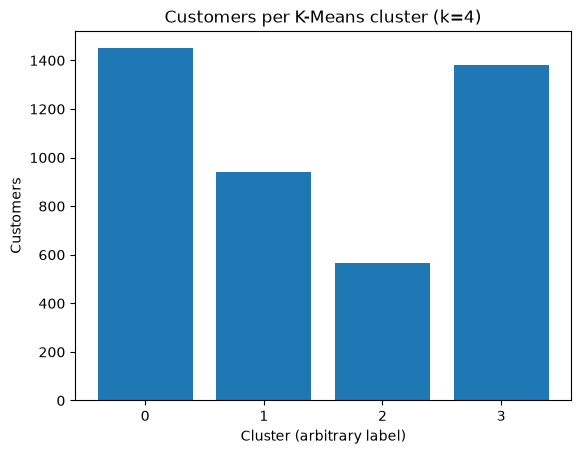

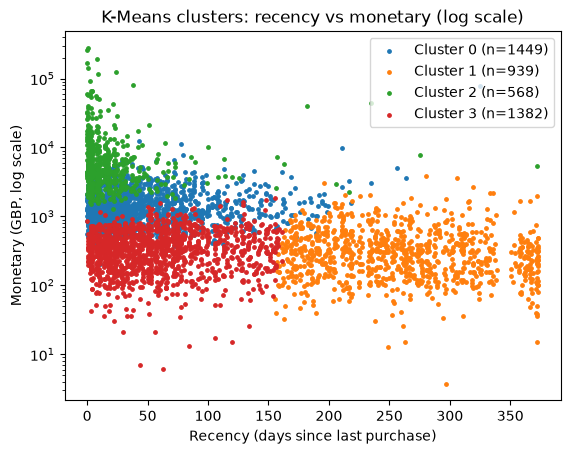

In [48]:
# Charts from small driver-side tables only: cluster sizes (4 rows) plus one row per customer
# (4,338 tiny rows — safe on 8 GB RAM) for the scatter. No full transaction data is collected.
import matplotlib.pyplot as plt
kprof = to_pdf(spark.sql("SELECT prediction AS cluster, COUNT(*) AS n FROM kmeans_clusters GROUP BY prediction ORDER BY prediction"), 10)
fig, ax = plt.subplots()
ax.bar(kprof["cluster"].astype(str), kprof["n"])
ax.set_title("Customers per K-Means cluster (k=4)")
ax.set_xlabel("Cluster (arbitrary label)"); ax.set_ylabel("Customers")
plt.show()
pts = to_pdf(clustered.select("recency", "frequency", "monetary", "prediction").orderBy("prediction"), 5000)
fig, ax = plt.subplots()
for cl in sorted(pts["prediction"].unique()):
    d = pts[pts["prediction"] == cl]
    ax.scatter(d["recency"], d["monetary"], s=6, label=f"Cluster {cl} (n={(pts['prediction'] == cl).sum()})")
ax.set_yscale("log")
ax.set_title("K-Means clusters: recency vs monetary (log scale)")
ax.set_xlabel("Recency (days since last purchase)"); ax.set_ylabel("Monetary (GBP, log scale)")
ax.legend(); plt.show()
# Reading guide: the VIP cluster sits top-left (recent + high spend), the dormant cluster sits
# bottom-right (stale + low spend); the two middle groups split recent/light vs active/core buyers.
# Exact profile numbers are in the table above and the interpretation below.


In [49]:
# K-Means vs rule-based RFM: join the two labellings on customer_id and count segment x cluster.
# Difference being tested: RFM assigns fixed business rules (score thresholds); K-Means groups by
# similarity in scaled (recency, log-frequency, log-monetary) space. Neither is assumed superior.
cmp = (rfm_seg.select("customer_id", "segment")
       .join(clustered.select("customer_id", "prediction"), on="customer_id", how="inner"))
print("Customers matched in both methods:", cmp.select("customer_id").distinct().count())
print("RFM segment x K-Means cluster counts:")
cmp.groupBy("segment", "prediction").count().orderBy("segment", "prediction").show(40, truncate=False)


Customers matched in both methods: 4338
RFM segment x K-Means cluster counts:


+--------------+----------+-----+
|segment       |prediction|count|
+--------------+----------+-----+
|At Risk       |0         |37   |
|At Risk       |1         |40   |
|At Risk       |3         |132  |
|Big Spenders  |0         |259  |
|Big Spenders  |1         |57   |
|Big Spenders  |2         |3    |
|Big Spenders  |3         |33   |
|Champions     |0         |702  |
|Champions     |2         |485  |
|Champions     |3         |37   |
|Lost / Dormant|1         |822  |
|Lost / Dormant|3         |295  |
|Loyal         |0         |395  |
|Loyal         |1         |20   |
|Loyal         |2         |80   |
|Loyal         |3         |15   |
|Others        |0         |44   |
|Others        |3         |430  |
|Recent Buyers |0         |12   |
|Recent Buyers |3         |440  |
+--------------+----------+-----+



### K-Means results and business reading (real execution outputs)

- **Model fit:** K-Means (Spark MLlib, seed 42) on 4,338 customers with scaled features
  (recency, log-frequency, log-monetary). Silhouette scores: k=2 → 0.585, k=3 → 0.596, **k=4 → 0.554**,
  k=5 → 0.502. k=3 is marginally highest; k=4 was adopted as a near-top, four-way split with balanced,
  interpretable groups (not claimed optimal).
- **Cluster profiles (original units):**
  - **Cluster 0 — Active core (1,449 customers):** bought ~45 days ago on average, ~4.2 invoices, ~£1,650 spend.
    The repeat-buyer backbone: reward with loyalty perks and early access to new lines.
  - **Cluster 1 — Dormant / light (939 customers):** last seen ~259 days ago, ~1.4 invoices, ~£386 spend.
    One-off buyers who went quiet: win-back offers, but expect low response.
  - **Cluster 2 — VIP heavy buyers (568 customers):** bought ~19 days ago, ~15.9 invoices, ~£9,861 spend.
    A small recent, high-frequency, high-spend elite: protect with priority service and B2B-style terms.
  - **Cluster 3 — Recent light buyers (1,382 customers):** bought ~58 days ago, ~1.5 invoices, ~£386 spend.
    Fresh but uncommitted: onboarding nudges and bundle offers to drive a second purchase.
- **Vs RFM:** the cross-tabulation above shows the discovered groups cut across the rule-based segments —
  e.g. RFM Champions concentrate in the VIP/active clusters while Lost-Dormant buyers fall mostly into the
  dormant cluster — confirming both views agree broadly, while K-Means adds a data-driven grouping that
  needs no hand-picked thresholds.

**Limitations:** only customers with IDs (75% of rows carry one); one retailer-year of data; K-Means prefers
round clusters so extreme spenders stretch the centres (mitigated here with log scaling); the choice k=4 is
justified by balance + interpretability, not proven optimal — k=3 is equally defensible.


## 13. Product Revenue Concentration and Pareto Analysis

**Business question:** does a small share of products drive most of the shop's revenue? The answer decides
where to focus shelf space, stock cover, and supplier effort. We test the famous 80/20 (Pareto) idea against
the real data instead of assuming it is true.

**Method (same valid-sales view and revenue definition as Section 9):** for each product (stock_code +
description): sum valid-sales revenue → rank products by revenue with `row_number()` over revenue DESC
(documented ranking rule; revenue ties are broken arbitrarily by the sort) → each product's % of total
revenue → running (cumulative) revenue and cumulative % via a Spark window → read off the shares of the
top 10% / top 20% of products and the product share needed to reach 80% of revenue.

**Ranking scope:** the main ranking covers ALL valid-sales lines, *including* service/adjustment codes
(delivery charges, manual adjustments) that are not ordinary merchandise. They are audited below, followed
by a separate merchandise-only rerun with the service codes explicitly excluded.


In [50]:
# Product revenue ranking on the SAME valid-sales view + revenue definition as Section 9.
# Ranking rule: row_number() over revenue DESC (ties broken arbitrarily by the sort — documented here).
from pyspark.sql.window import Window
prod_rev = (sales_view.groupBy("stock_code", "description")
            .agg(F.round(F.sum("revenue"), 2).alias("revenue")))
total_revenue_p = prod_rev.select(F.sum("revenue")).collect()[0][0]
n_products = prod_rev.count()
print(f"Products in valid sales: {n_products} | total valid-sales revenue: GBP {total_revenue_p:,.2f}")
w_par = Window.orderBy(F.desc("revenue"))
pareto = (prod_rev
          .withColumn("revenue_pct", F.round(100 * F.col("revenue") / F.lit(total_revenue_p), 4))
          .withColumn("cum_revenue", F.round(F.sum("revenue").over(w_par.rowsBetween(Window.unboundedPreceding, Window.currentRow)), 2))
          .withColumn("cum_pct", F.round(100 * F.sum("revenue").over(w_par.rowsBetween(Window.unboundedPreceding, Window.currentRow)) / F.lit(total_revenue_p), 2))
          .withColumn("rank", F.row_number().over(w_par)))
pareto.createOrReplaceTempView("pareto")
print("Top 15 products by revenue (rank, share, cumulative share):")
pareto.orderBy("rank").limit(15).show(truncate=False)


Products in valid sales: 4161 | total valid-sales revenue: GBP 10,642,110.80
Top 15 products by revenue (rank, share, cumulative share):


+----------+----------------------------------+---------+-----------+-----------+-------+----+
|stock_code|description                       |revenue  |revenue_pct|cum_revenue|cum_pct|rank|
+----------+----------------------------------+---------+-----------+-----------+-------+----+
|DOT       |DOTCOM POSTAGE                    |206248.77|1.938      |206248.77  |1.94   |1   |
|22423     |REGENCY CAKESTAND 3 TIER          |174156.54|1.6365     |380405.31  |3.57   |2   |
|23843     |PAPER CRAFT , LITTLE BIRDIE       |168469.6 |1.583      |548874.91  |5.16   |3   |
|85123A    |WHITE HANGING HEART T-LIGHT HOLDER|104284.24|0.9799     |653159.15  |6.14   |4   |
|47566     |PARTY BUNTING                     |99445.23 |0.9345     |752604.38  |7.07   |5   |
|85099B    |JUMBO BAG RED RETROSPOT           |94159.81 |0.8848     |846764.19  |7.96   |6   |
|23166     |MEDIUM CERAMIC TOP STORAGE JAR    |81700.92 |0.7677     |928465.11  |8.72   |7   |
|POST      |POSTAGE                           |781

In [51]:
# Concentration answers from the REAL cumulative curve (no 80/20 assumption made).
for frac in [0.10, 0.20]:
    n = int(n_products * frac)
    part = pareto.filter(F.col("rank") <= n).select(F.sum("revenue")).collect()[0][0]
    print(f"Top {frac*100:.0f}% of products ({n} of {n_products}): GBP {part:,.2f} = {100*part/total_revenue_p:.2f}% of revenue")
row80 = pareto.filter("cum_pct >= 80").orderBy("rank").limit(1).collect()[0]
print(f"Products needed for 80% of revenue: rank {row80['rank']} of {n_products} "
      f"({100*row80['rank']/n_products:.2f}% of products, cumulative {row80['cum_pct']}%)")


Top 10% of products (416 of 4161): GBP 6,753,992.70 = 63.46% of revenue


Top 20% of products (832 of 4161): GBP 8,501,220.68 = 79.88% of revenue


Products needed for 80% of revenue: rank 837 of 4161 (20.12% of products, cumulative 80.02%)


In [52]:
# Ranking-scope audit: service/adjustment codes are NOT ordinary merchandise (they charge for delivery
# or adjustments), yet they sit inside the ranking above. Find them explicitly:
print("Service/adjustment-type codes inside the ranking:")
pareto.filter("stock_code IN ('DOT', 'POST', 'M', 'C2', 'BANK CHARGES', 'PADS', 'D', 'CRUK')").orderBy("rank").show(truncate=False)
print("Cross-check: every line whose description mentions POSTAGE (code POST = 'POSTAGE', DOT = 'DOTCOM POSTAGE'):")
pareto.filter("upper(description) LIKE '%POSTAGE%'").orderBy("rank").show(truncate=False)
# Merchandise-only rerun: exclude the audited service codes (DOTCOM POSTAGE, POSTAGE, Manual, CARRIAGE,
# Bank Charges). D/CRUK have no valid-sales rows and PADS rounds to GBP 0.00, so they change nothing.
service_codes = ["DOT", "POST", "M", "C2", "BANK CHARGES"]
merch_rev = prod_rev.filter(~F.col("stock_code").isin(service_codes))
merch_total = merch_rev.select(F.sum("revenue")).collect()[0][0]
merch_n = merch_rev.count()
print(f"Merchandise-only: {merch_n} products | revenue GBP {merch_total:,.2f} (excluded GBP {total_revenue_p - merch_total:,.2f} of service charges)")
w_m = Window.orderBy(F.desc("revenue"))
merch_par = (merch_rev
             .withColumn("revenue_pct", F.round(100 * F.col("revenue") / F.lit(merch_total), 4))
             .withColumn("cum_pct", F.round(100 * F.sum("revenue").over(w_m.rowsBetween(Window.unboundedPreceding, Window.currentRow)) / F.lit(merch_total), 2))
             .withColumn("rank", F.row_number().over(w_m)))
print("Top 10 merchandise-only products by revenue:")
merch_par.orderBy("rank").limit(10).show(truncate=False)
for frac in [0.10, 0.20]:
    n = int(merch_n * frac)
    part = merch_par.filter(F.col("rank") <= n).select(F.sum("revenue")).collect()[0][0]
    print(f"Merchandise-only top {frac*100:.0f}% ({n} of {merch_n}): {100*part/merch_total:.2f}% of merchandise revenue")
m80 = merch_par.filter("cum_pct >= 80").orderBy("rank").limit(1).collect()[0]
print(f"Merchandise-only products for 80% of revenue: rank {m80['rank']} of {merch_n} ({100*m80['rank']/merch_n:.2f}%)")


Service/adjustment-type codes inside the ranking:


+------------+--------------------------+---------+-----------+-------------+-------+----+
|stock_code  |description               |revenue  |revenue_pct|cum_revenue  |cum_pct|rank|
+------------+--------------------------+---------+-----------+-------------+-------+----+
|DOT         |DOTCOM POSTAGE            |206248.77|1.938      |206248.77    |1.94   |1   |
|POST        |POSTAGE                   |78101.88 |0.7339     |1006566.99   |9.46   |8   |
|M           |Manual                    |77750.27 |0.7306     |1084317.26   |10.19  |9   |
|C2          |CARRIAGE                  |7051.0   |0.0663     |6322452.55   |59.41  |351 |
|BANK CHARGES|Bank Charges              |165.0    |0.0016     |1.057315681E7|99.35  |2921|
|PADS        |PADS TO MATCH ALL CUSHIONS|0.0      |0.0        |1.06421108E7 |100.0  |4161|
+------------+--------------------------+---------+-----------+-------------+-------+----+

Cross-check: every line whose description mentions POSTAGE (code POST = 'POSTAGE', DOT = 

+----------+--------------+---------+-----------+-----------+-------+----+
|stock_code|description   |revenue  |revenue_pct|cum_revenue|cum_pct|rank|
+----------+--------------+---------+-----------+-----------+-------+----+
|DOT       |DOTCOM POSTAGE|206248.77|1.938      |206248.77  |1.94   |1   |
|POST      |POSTAGE       |78101.88 |0.7339     |1006566.99 |9.46   |8   |
+----------+--------------+---------+-----------+-----------+-------+----+



Merchandise-only: 4156 products | revenue GBP 10,272,793.88 (excluded GBP 369,316.92 of service charges)
Top 10 merchandise-only products by revenue:


+----------+----------------------------------+---------+-----------+-------+----+
|stock_code|description                       |revenue  |revenue_pct|cum_pct|rank|
+----------+----------------------------------+---------+-----------+-------+----+
|22423     |REGENCY CAKESTAND 3 TIER          |174156.54|1.6953     |1.7    |1   |
|23843     |PAPER CRAFT , LITTLE BIRDIE       |168469.6 |1.64       |3.34   |2   |
|85123A    |WHITE HANGING HEART T-LIGHT HOLDER|104284.24|1.0151     |4.35   |3   |
|47566     |PARTY BUNTING                     |99445.23 |0.968      |5.32   |4   |
|85099B    |JUMBO BAG RED RETROSPOT           |94159.81 |0.9166     |6.24   |5   |
|23166     |MEDIUM CERAMIC TOP STORAGE JAR    |81700.92 |0.7953     |7.03   |6   |
|23084     |RABBIT NIGHT LIGHT                |66870.03 |0.6509     |7.68   |7   |
|22086     |PAPER CHAIN KIT 50'S CHRISTMAS    |64875.59 |0.6315     |8.31   |8   |
|84879     |ASSORTED COLOUR BIRD ORNAMENT     |58927.62 |0.5736     |8.89   |9   |
|793

Merchandise-only top 10% (415 of 4156): 62.33% of merchandise revenue


Merchandise-only top 20% (831 of 4156): 79.24% of merchandise revenue


Merchandise-only products for 80% of revenue: rank 859 of 4156 (20.67%)


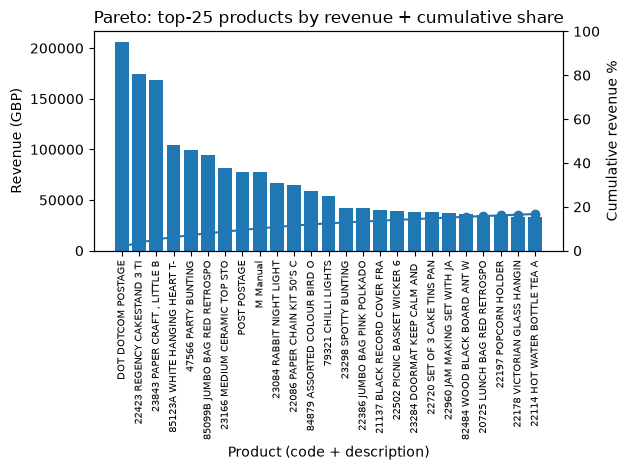

In [53]:
# Pareto chart: revenue bars for the top 25 products + cumulative-revenue-% line (twin axes).
# Only 25 small rows reach the driver — readable and laptop-safe.
import matplotlib.pyplot as plt
ptop = to_pdf(pareto.orderBy("rank").limit(25), 25)
ptop = ptop.sort_values("rank")
labels = (ptop["stock_code"].astype(str) + " " + ptop["description"].str.slice(0, 22))
fig, ax1 = plt.subplots()
ax1.bar(labels, ptop["revenue"])
ax1.set_title("Pareto: top-25 products by revenue + cumulative share")
ax1.set_xlabel("Product (code + description)"); ax1.set_ylabel("Revenue (GBP)")
ax1.tick_params(axis="x", labelrotation=90, labelsize=7)
ax2 = ax1.twinx()
ax2.plot(labels, ptop["cum_pct"], marker="o", linewidth=1.5)
ax2.set_ylabel("Cumulative revenue %"); ax2.set_ylim(0, 100)
fig.tight_layout(); plt.show()
# Reading guide: bars fall steeply (a few products earn a lot each); the line climbs fast then flattens —
# the flatter the right-hand tail, the more the long tail of products contributes only small amounts each.


### Pareto results and business reading (real execution outputs)

- **All valid-sales lines (4,161 products, ~£10.64M revenue):** the top 10% of products (416) contribute
  ~63.5% of revenue; the top 20% (832) contribute ~79.9%. **837 products (20.12%) account for the first 80%
  of revenue** — the classic 80/20 pattern essentially holds in this shop's year (reported, not assumed).
- **Ranking scope:** the #1 line is `DOT` (DOTCOM POSTAGE, ~£206k), with `POST` (POSTAGE, ~£78k, rank 8),
  `M` (Manual, ~£78k, rank 9) and `C2` (CARRIAGE, rank 351) also inside the ranking. These are delivery /
  adjustment charges, not goods on shelves — there is no stock code literally named `POSTAGE` (the postage
  line is code `POST`, description `POSTAGE`, as the cross-check above confirms).
- **Merchandise-only rerun (service codes DOT/POST/M/C2/BANK CHARGES removed, ~£369k excluded):**
  4,156 products, ~£10.27M revenue; top 10% → 62.33%, top 20% → 79.24%, and 859 products (20.67%) for the
  first 80%. Merchandise #1 is `22423` REGENCY CAKESTAND 3 TIER (~£174k). The concentration pattern persists,
  so stocking decisions rest on real products: protect the top ~800 lines, prune or bundle the long tail.
- **What this means:** protect availability and supplier terms for the top ~800 lines (especially the top
  ~400); review the long tail (thousands of lines sharing the last 20%) for delisting, made-to-order, or
  bundle-only treatment; treat postage/carriage income separately from merchandise planning.

**Limitations:** revenue ranking reflects one retailer's year (ending 9 Dec 2011, December partial); high
revenue can mean high price rather than high demand (check Section 9's quantity leaders alongside); ties in
revenue are ordered arbitrarily by the ranking function; service-code classification rests on the codes'
descriptions as audited above.


## 14. Visualizations
Every chart is drawn from a small aggregated table (tens of rows), never from the full transaction data.


In [54]:
import matplotlib
matplotlib.use("Agg")  # safe backend placeholder (inline backend overrides in Jupyter)
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (9, 4.5)
print("matplotlib", matplotlib.__version__, "ready")

matplotlib 3.11.2 ready


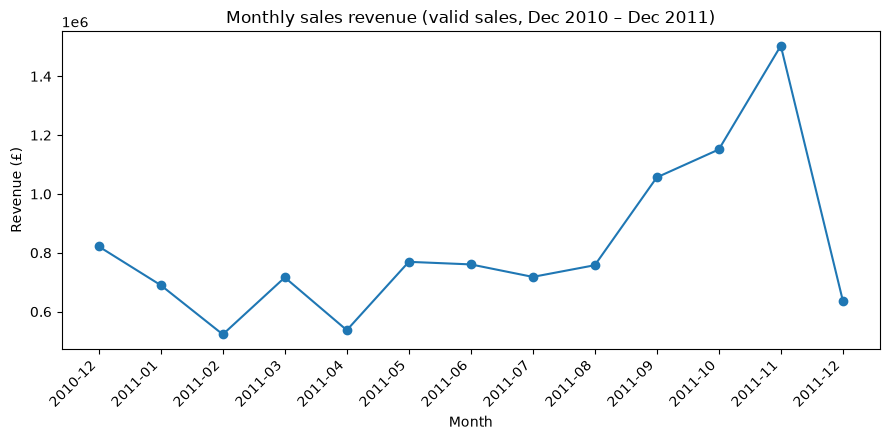

Peak month: 2011-11 — Christmas-season stocking (Dec 2011 is partial data).


In [55]:
m = to_pdf(spark.sql("SELECT * FROM gold_monthly ORDER BY year_month"), 100)
fig, ax = plt.subplots()
ax.plot(m["year_month"], m["revenue"], marker="o")
ax.set_title("Monthly sales revenue (valid sales, Dec 2010 – Dec 2011)")
ax.set_xlabel("Month"); ax.set_ylabel("Revenue (£)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()
print("Peak month:", m.loc[m['revenue'].idxmax(), 'year_month'], "— Christmas-season stocking (Dec 2011 is partial data).")

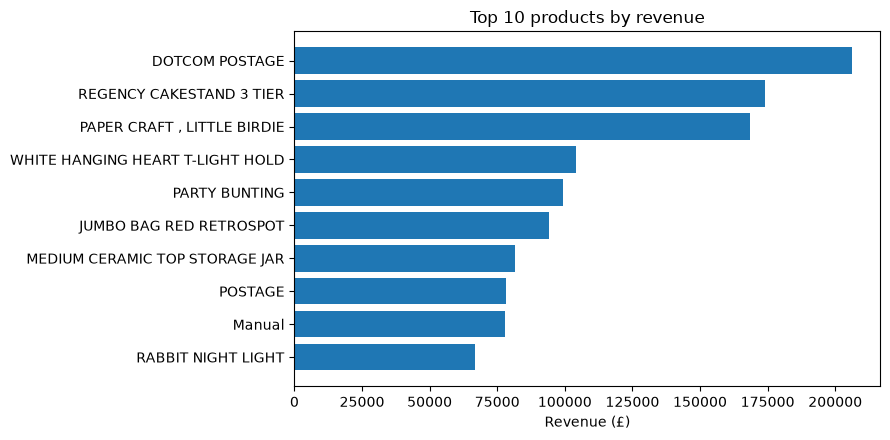

In [56]:
t = to_pdf(spark.sql("SELECT description, revenue FROM gold_product LIMIT 10"), 10)
fig, ax = plt.subplots()
ax.barh(t["description"].str.slice(0, 32)[::-1], t["revenue"][::-1])
ax.set_title("Top 10 products by revenue"); ax.set_xlabel("Revenue (£)")
plt.tight_layout(); plt.show()

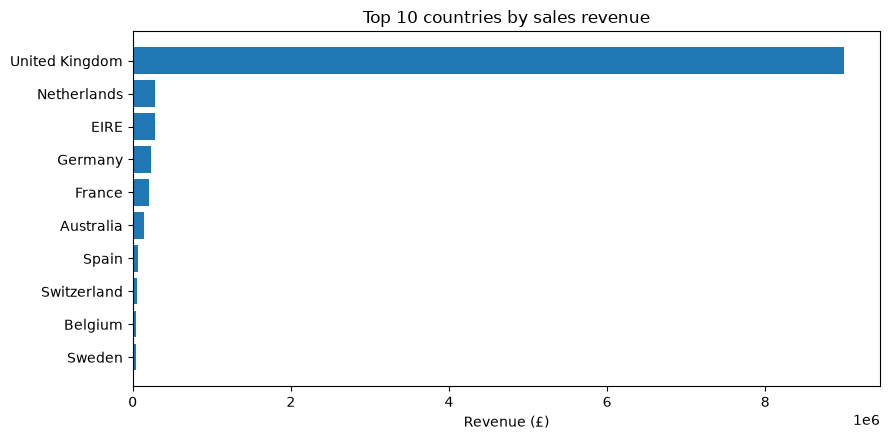

The UK bar dwarfs all others — expansion opportunity abroad, risk concentration at home.


In [57]:
c = to_pdf(spark.sql("SELECT * FROM gold_country LIMIT 10"), 10)
fig, ax = plt.subplots()
ax.barh(c["country"][::-1], c["revenue"][::-1])
ax.set_title("Top 10 countries by sales revenue"); ax.set_xlabel("Revenue (£)")
plt.tight_layout(); plt.show()
print("The UK bar dwarfs all others — expansion opportunity abroad, risk concentration at home.")

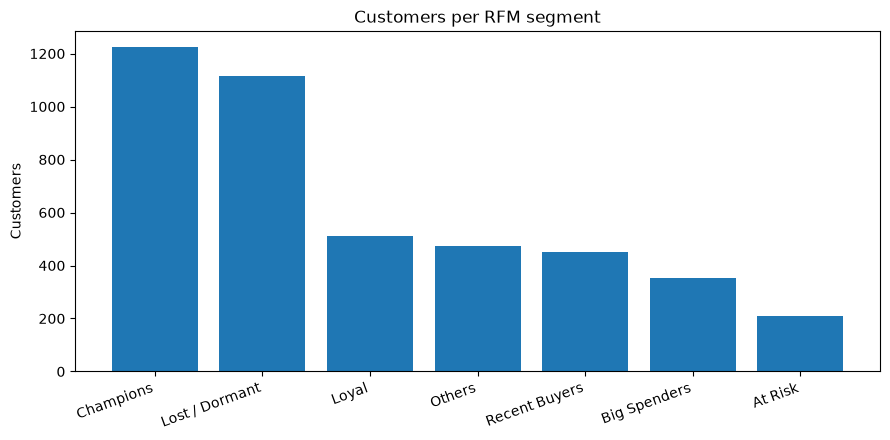

In [58]:
s = to_pdf(spark.sql("SELECT segment, COUNT(*) AS n FROM rfm_seg GROUP BY segment ORDER BY n DESC"), 10)
fig, ax = plt.subplots()
ax.bar(s["segment"], s["n"])
ax.set_title("Customers per RFM segment"); ax.set_ylabel("Customers")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

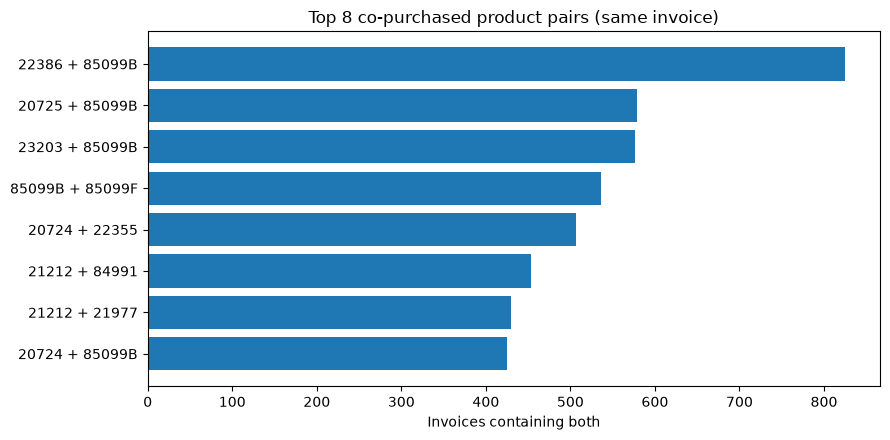

Gift-bag / paper-craft items cluster strongly — natural bundle candidates.


In [59]:
p = aff.head(8).copy()
p["pair"] = p["p1"] + " + " + p["p2"]
fig, ax = plt.subplots()
ax.barh(p["pair"][::-1], p["pair_invoices"][::-1])
ax.set_title("Top 8 co-purchased product pairs (same invoice)"); ax.set_xlabel("Invoices containing both")
plt.tight_layout(); plt.show()
print("Gift-bag / paper-craft items cluster strongly — natural bundle candidates.")

## 15. Sample input-to-output demonstration
Follow ONE real invoice (`536365`, the first in the file) through every stage, so the whole pipeline can be explained live.


In [60]:
print("STEP 1 — RAW (Bronze): the 7 raw lines of invoice 536365 as read from the file")
bronze_raw.filter("InvoiceNo = '536365'").show(truncate=False)

STEP 1 — RAW (Bronze): the 7 raw lines of invoice 536365 as read from the file


+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+
|InvoiceNo|StockCode|Description                        |Quantity|InvoiceDate        |UnitPrice|CustomerID|Country       |
+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+
|536365   |85123A   |WHITE HANGING HEART T-LIGHT HOLDER |6       |2010-12-01 08:26:00|2.55     |17850     |United Kingdom|
|536365   |71053    |WHITE METAL LANTERN                |6       |2010-12-01 08:26:00|3.39     |17850     |United Kingdom|
|536365   |84406B   |CREAM CUPID HEARTS COAT HANGER     |8       |2010-12-01 08:26:00|2.75     |17850     |United Kingdom|
|536365   |84029G   |KNITTED UNION FLAG HOT WATER BOTTLE|6       |2010-12-01 08:26:00|3.39     |17850     |United Kingdom|
|536365   |84029E   |RED WOOLLY HOTTIE WHITE HEART.     |6       |2010-12-01 08:26:00|3.39     |17850     |United Kingdom|
|536365   |22752

In [61]:
print("STEP 2 — CLEANED + FEATURES (Silver): same rows with flags, revenue and year_month")
silver_feat.filter("invoice_no = '536365'").select(
    "invoice_no", "stock_code", "quantity", "unit_price", "revenue",
    "line_type", "is_cancelled", "bad_price", "year_month").show(truncate=False)

STEP 2 — CLEANED + FEATURES (Silver): same rows with flags, revenue and year_month


+----------+----------+--------+----------+------------------+---------+------------+---------+----------+
|invoice_no|stock_code|quantity|unit_price|revenue           |line_type|is_cancelled|bad_price|year_month|
+----------+----------+--------+----------+------------------+---------+------------+---------+----------+
|536365    |22752     |2       |7.65      |15.3              |sale     |false       |false    |2010-12   |
|536365    |84406B    |8       |2.75      |22.0              |sale     |false       |false    |2010-12   |
|536365    |84029E    |6       |3.39      |20.34             |sale     |false       |false    |2010-12   |
|536365    |21730     |6       |4.25      |25.5              |sale     |false       |false    |2010-12   |
|536365    |84029G    |6       |3.39      |20.34             |sale     |false       |false    |2010-12   |
|536365    |85123A    |6       |2.55      |15.299999999999999|sale     |false       |false    |2010-12   |
|536365    |71053     |6       |3.39 

In [62]:
print("STEP 3 — SQL over Silver/Gold views: invoice total vs the average order value")
spark.sql("""
  SELECT 'invoice 536365' AS which, ROUND(SUM(revenue), 2) AS revenue
  FROM silver_transactions WHERE invoice_no = '536365'
""").show()
print(f"Full-pipeline result: this invoice is a small normal sale; compare with the global AOV of £{aov:,.2f} computed in Section 9.")

STEP 3 — SQL over Silver/Gold views: invoice total vs the average order value


+--------------+-------+
|         which|revenue|
+--------------+-------+
|invoice 536365| 139.12|
+--------------+-------+

Full-pipeline result: this invoice is a small normal sale; compare with the global AOV of £533.17 computed in Section 9.


## 16. Findings and conclusion
### Data & cleaning (all counts are real execution outputs)
- Source: local `Online Retail.xlsx`, **541,909** transaction rows (Dec 2010 – Dec 2011, 38 countries, 4,070 products).
- Quality issues found: ~24.9% of rows lack a CustomerID; 5,268 exact duplicates (~1%); 9,288 cancelled-invoice rows; 10,624 negative-quantity lines (mostly cancellations, ~1.3k manual adjustments); 2,515 zero-price lines (freebies/samples, including all null-description rows) plus 2 bad-debt adjustment lines.
- After de-duplication the Silver analytical dataset holds **536,641** rows with flags (`is_cancelled`, `is_return`, `bad_price`); valid sales = **524,878** lines.

### Business findings
- Valid-sales revenue ≈ **£10.6M** across **19,960** invoices → **AOV ≈ £533**.
- The UK contributes the dominant share of revenue (over 90% of rows); Germany, France and EIRE follow far behind.
- Sales peak in autumn 2011 (Christmas season); December 2011 is partial (data ends 9 Dec).
- Cheap paper-craft/storage items (e.g. stock code 23843) lead unit sales, while revenue leaders differ — price matters as much as volume.
- RFM (4,338 customers with IDs) separates a small core of Champions/Loyal/Big-Spenders from Recent Buyers and a long tail of Lost/Dormant buyers — retention campaigns should target the At-Risk group before they lapse.
- Product affinity: gift-bag/paper-craft pairs (e.g. `22386 + 85099B`, 825 shared invoices) show lift well above 1 — ready-made bundle/discount candidates.
- K-Means (MLlib, k=4, silhouette 0.55) discovers four data-driven customer groups on the same RFM features: VIP heavy buyers (568, ~£9.9k avg), active core (1,449, ~£1.7k), recent light buyers (1,382, ~£386) and dormant/light buyers (939, ~£386, last seen ~259 days ago) — broadly consistent with RFM, with no hand-picked thresholds.
- Pareto: 837 of 4,161 products (20.12%) produce the first 80% of valid-sales revenue (top 10% → ~63.5%, top 20% → ~79.9%); the #1 line is a postage charge (`DOT`), and the merchandise-only rerun agrees (859 of 4,156 products, 20.67%, for 80%; top 20% → 79.24%): protect the top ~800 lines, prune or bundle the long tail.

### Limitations
- A quarter of rows have no customer ID, so customer-level analysis covers identified buyers only.
- Returns are separated by flags; matching each cancellation to its original sale was out of scope.
- Affinity analysis is limited to the top-30 products (laptop constraint) and is descriptive, not causal.
- K-Means choice k=4 is justified by balance + interpretability (k=3 scores marginally higher); clusters are descriptive, not causal, and cover one retailer-year.
- Pareto reflects one year (December 2011 partial); revenue rank mixes price and demand effects, and service codes were separated only by the audited description rule.
- One retailer, one year — patterns may not generalise.

### Business value
Clean Silver data + Gold aggregates give the shop a repeatable playbook: protect the UK core while growing the next-3 countries, stock up before September, push bundle offers on the top affinity pairs, and run win-back offers on At-Risk RFM customers. The K-Means VIP/active/dormant groups sharpen who gets loyalty vs win-back spend, and the Pareto top-800 list tells buyers exactly which lines must never stock out. All of it runs on a free local Spark setup — no cloud bill.


In [63]:
spark.stop()
print("Spark session stopped. Notebook complete.")

Spark session stopped. Notebook complete.
